# M02: K-Means Clustering Baseline Analysis

**Mục tiêu:** Khảo sát thực nghiệm phân cụm từ vựng chuẩn (Lexical Clustering Baseline) trên ma trận TF-IDF 20,000 chiều từ Task M01.  
**Cấu hình tối ưu được chọn:** $K = 9$


## 1. Thiết lập Môi trường & Nạp Thư viện

In [52]:
import json
import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_samples, silhouette_score

# Cấu hình đường dẫn thư mục gốc dự án
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "vietnamese-news-topic-discovery" else Path(".").resolve()
FIGURES_DIR = PROJECT_ROOT / "results" / "kmeans" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình giao diện biểu đồ
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# print(f"Project root: {PROJECT_ROOT}")
# print(f"Figures dir:  {FIGURES_DIR}")


## 2. Khảo sát Số cụm (K-Search & Model Selection)
Khảo sát số cụm $K \in [3, 5, 7, 9, 11, 14, 18]$ neo quanh 7 chuyên mục gốc (`category_gold`).
- **Chỉ số nội tại (Unsupervised):** Inertia (Elbow), Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz.
- **Chỉ số ngoại vi (Supervised Post-Clustering):** ARI, NMI, Purity đối chiếu với `category_gold` (chỉ đo sau khi phân cụm trên tập Validation; tuyệt đối Zero Label Leakage).
- **Độ ổn định (Multi-seed Stability):** Đánh giá Mean ARI qua 5 seed ngẫu nhiên [42, 43, 44, 45, 46].


In [53]:
metrics_path = PROJECT_ROOT / "results" / "kmeans" / "kmeans_k_search_metrics.csv"
metrics_df = pd.read_csv(metrics_path)

# Hiển thị bảng số liệu khảo sát K với định dạng trực quan
display_cols = [
    "k", "train_inertia", "val_inertia", "silhouette_score",
    "davies_bouldin_index", "ari", "nmi", "purity",
    "stability_ari_mean", "min_cluster_size_val", "is_selected"
]
metrics_df[display_cols].style.highlight_max(
    subset=["silhouette_score", "nmi", "purity", "stability_ari_mean"], color="#4a69d6"
).highlight_min(
    subset=["davies_bouldin_index"], color="#4a69d6"
)


,k,train_inertia,val_inertia,silhouette_score,davies_bouldin_index,ari,nmi,purity,stability_ari_mean,min_cluster_size_val,is_selected
0,3,6049.340000,1295.950000,0.014700,7.148900,0.255300,0.479000,0.509700,0.848600,218,False
1,5,5961.880000,1276.680000,0.018900,7.194100,0.560600,0.656600,0.723900,0.917000,163,False
2,7,5898.320000,1264.160000,0.020500,6.617800,0.623900,0.688900,0.821000,0.827700,90,False
3,9,5844.770000,1253.450000,0.019000,6.156600,0.592500,0.700400,0.872800,0.822400,76,True
4,11,5797.530000,1242.720000,0.020500,5.826100,0.489900,0.645700,0.824600,0.805600,30,False
5,14,5748.230000,1234.100000,0.019400,5.628700,0.437600,0.626500,0.837500,0.699100,30,False
6,18,5698.950000,1226.100000,0.019100,5.602800,0.390800,0.622700,0.881400,0.712800,7,False


### 2.1. Biểu đồ Khuỷu tay: Elbow Method: Inertia vs K

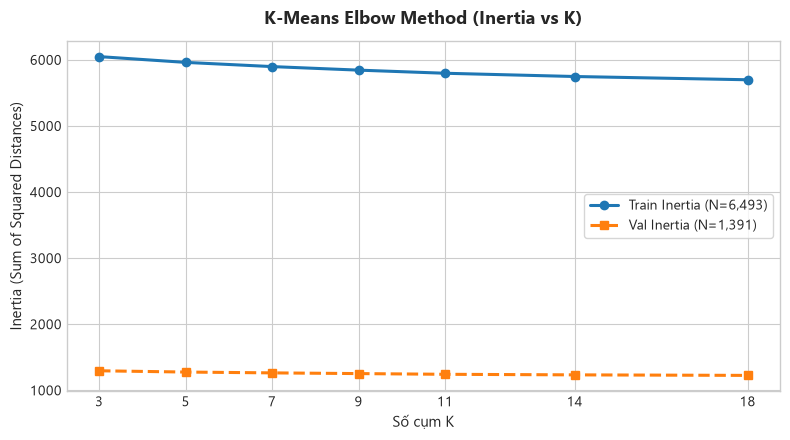

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(metrics_df["k"], metrics_df["train_inertia"], marker="o", color="#1f77b4", linewidth=2.2, label="Train Inertia (N=6,493)")
ax.plot(metrics_df["k"], metrics_df["val_inertia"], marker="s", color="#ff7f0e", linewidth=2.2, linestyle="--", label="Val Inertia (N=1,391)")

ax.set_title("K-Means Elbow Method (Inertia vs K)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Số cụm K", fontsize=11)
ax.set_ylabel("Inertia", fontsize=11)
ax.set_xticks(metrics_df["k"])
ax.legend(frameon=True, fontsize=10)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_elbow_inertia.png", dpi=300)
plt.show()


### 2.2. Biểu đồ Silhouette Score & Davies-Bouldin Index theo K

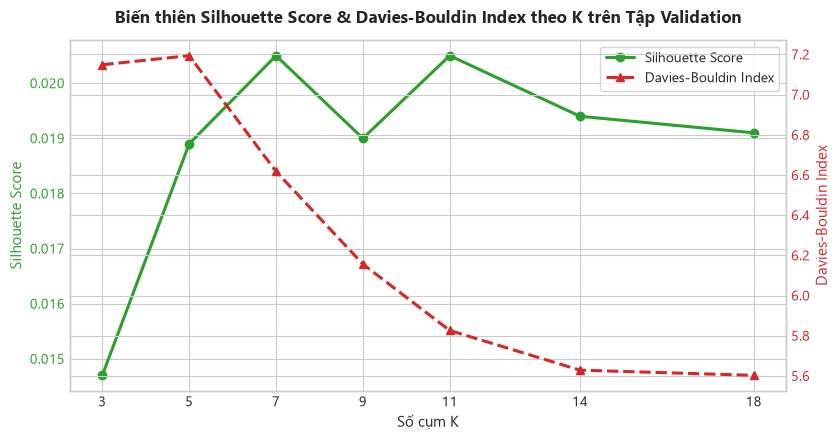

In [55]:
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
color1 = "#2ca02c"
color2 = "#d62728"

ax1.set_xlabel("Số cụm K", fontsize=11)
ax1.set_ylabel("Silhouette Score", color=color1, fontsize=11)
line1 = ax1.plot(metrics_df["k"], metrics_df["silhouette_score"], color=color1, marker="o", linewidth=2.2, label="Silhouette Score")
ax1.tick_params(axis="y", labelcolor=color1)
ax1.set_xticks(metrics_df["k"])

ax2 = ax1.twinx()
ax2.set_ylabel("Davies-Bouldin Index", color=color2, fontsize=11)
line2 = ax2.plot(metrics_df["k"], metrics_df["davies_bouldin_index"], color=color2, marker="^", linewidth=2.2, linestyle="--", label="Davies-Bouldin Index")
ax2.tick_params(axis="y", labelcolor=color2)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper right", frameon=True)
plt.title("Biến thiên Silhouette Score & Davies-Bouldin Index theo K trên Tập Validation", fontsize=12, fontweight="bold", pad=12)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_silhouette_davies.png", dpi=300)
plt.show()


### 2.3. Biểu đồ Phân tích Silhouette Từng Mẫu 

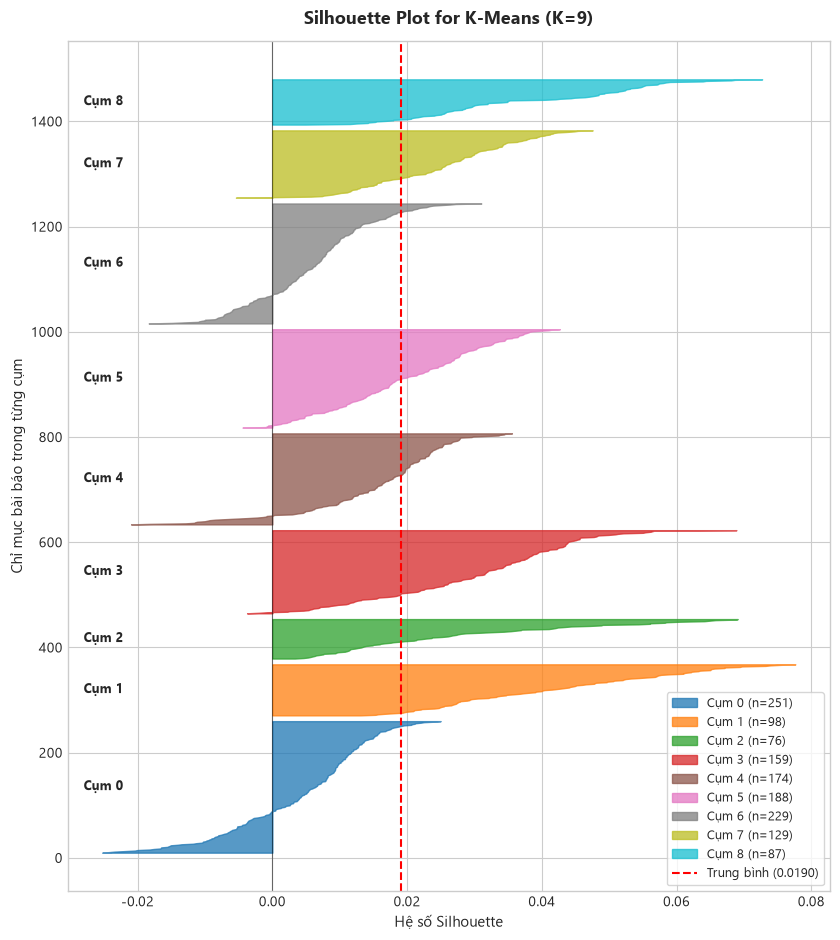

In [56]:
val_matrix = sp.load_npz(PROJECT_ROOT / "artifacts" / "tfidf" / "tfidf_val.npz")
model = joblib.load(PROJECT_ROOT / "artifacts" / "kmeans" / "kmeans_model.joblib")
val_labels = model.predict(val_matrix)
n_clusters = model.n_clusters

sil_avg = silhouette_score(val_matrix, val_labels)
sample_sil_values = silhouette_samples(val_matrix, val_labels)

fig, ax = plt.subplots(figsize=(8.5, 9.5))
y_lower = 10
colors = plt.cm.tab10(np.linspace(0, 1, n_clusters))

for i in range(n_clusters):
    ith_cluster_sil = sample_sil_values[val_labels == i]
    ith_cluster_sil.sort()
    size_cluster_i = ith_cluster_sil.shape[0]
    y_upper = y_lower + size_cluster_i
    
    color = colors[i]
    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        ith_cluster_sil,
        facecolor=color,
        edgecolor=color,
        alpha=0.75,
        label=f"Cụm {i} (n={size_cluster_i})"
    )
    ax.text(-0.028, y_lower + 0.5 * size_cluster_i, f"Cụm {i}", fontsize=9, va="center", fontweight="bold")
    y_lower = y_upper + 10

ax.set_title(f"Silhouette Plot for K-Means (K={n_clusters})", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Hệ số Silhouette", fontsize=11)
ax.set_ylabel("Chỉ mục bài báo trong từng cụm", fontsize=11)
ax.axvline(x=sil_avg, color="red", linestyle="--", linewidth=1.5, label=f"Trung bình ({sil_avg:.4f})")
ax.axvline(x=0, color="black", linestyle="-", linewidth=0.8, alpha=0.5)
ax.legend(loc="lower right", frameon=True, fontsize=9)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_silhouette_samples.png", dpi=300)
plt.show()


## 3. Phân bố Kích thước Cụm & Không gian Phân cụm 2D
- **Phân bố kích thước:** Kiểm tra xem mô hình có bị phân mảnh thành các cụm rác quá nhỏ (< 30 bài) hay không.
- **Không gian 2D:** Sử dụng kỹ thuật TruncatedSVD để giảm 20,000 chiều TF-IDF xuống 2 chiều trực quan.


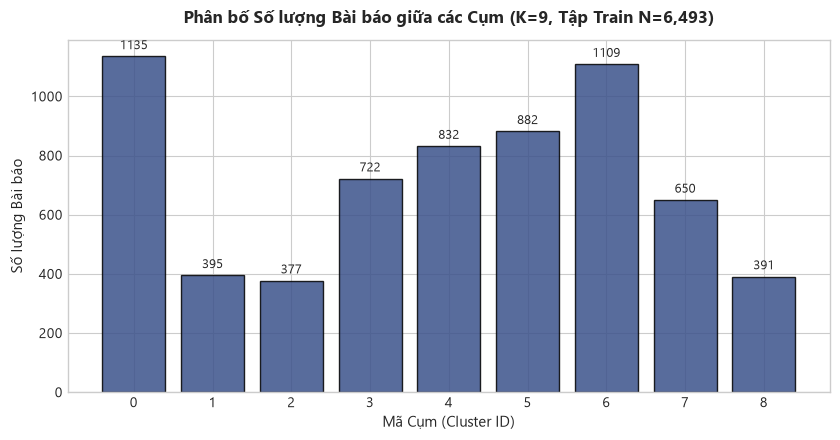

In [57]:
doc_topics_path = PROJECT_ROOT / "artifacts" / "kmeans" / "document_topics.csv"
doc_topics = pd.read_csv(doc_topics_path)

train_topics = doc_topics[doc_topics["split"] == "train"]
cluster_counts = train_topics["cluster_id"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values,
    color="#3b528b",
    edgecolor="black",
    alpha=0.85,
)

ax.set_title(f"Phân bố Số lượng Bài báo giữa các Cụm (K={len(cluster_counts)}, Tập Train N=6,493)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Mã Cụm (Cluster ID)", fontsize=11)
ax.set_ylabel("Số lượng Bài báo", fontsize=11)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, yval + 15, f"{int(yval)}", ha="center", va="bottom", fontsize=9.5)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_cluster_size_distribution.png", dpi=300)
plt.show()


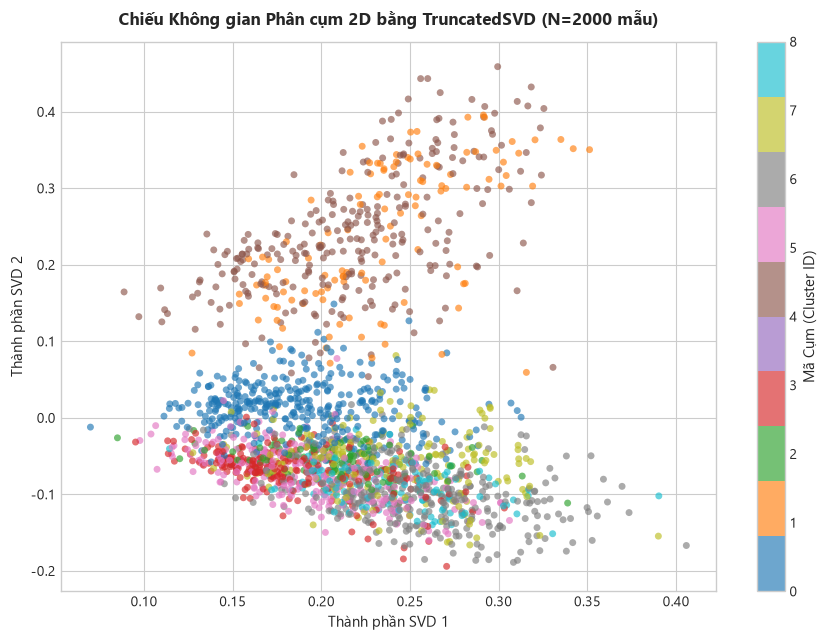

In [58]:
train_matrix = sp.load_npz(PROJECT_ROOT / "artifacts" / "tfidf" / "tfidf_train.npz")
train_labels = doc_topics[doc_topics["split"] == "train"]["cluster_id"].values

# Lấy mẫu 2,000 bài để trực quan hóa rõ nét, tránh chồng đè điểm ảnh
sample_size = min(2000, train_matrix.shape[0])
rng = np.random.RandomState(42)
sample_indices = rng.choice(train_matrix.shape[0], size=sample_size, replace=False)
sample_matrix = train_matrix[sample_indices]
sample_labels = train_labels[sample_indices]

svd = TruncatedSVD(n_components=2, random_state=42)
coords_2d = svd.fit_transform(sample_matrix)

fig, ax = plt.subplots(figsize=(9, 6.5))
cmap = plt.get_cmap("tab10" if len(cluster_counts) <= 10 else "tab20")
scatter = ax.scatter(
    coords_2d[:, 0],
    coords_2d[:, 1],
    c=sample_labels,
    cmap=cmap,
    alpha=0.65,
    s=25,
    edgecolors="none",
)

cbar = plt.colorbar(scatter, ax=ax, ticks=range(len(cluster_counts)))
cbar.set_label("Mã Cụm (Cluster ID)", fontsize=11)
ax.set_title(f"Chiếu Không gian Phân cụm 2D bằng TruncatedSVD (N={sample_size} mẫu)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Thành phần SVD 1", fontsize=11)
ax.set_ylabel("Thành phần SVD 2", fontsize=11)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_2d_clusters.png", dpi=300)
plt.show()


## 4. Từ khóa Tiêu biểu Từng cụm (Centroid Top Keywords for K=9)
Trích xuất từ ma trận tâm cụm (centroid matrix) trên không gian TF-IDF 20,000 chiều.


In [59]:
with open(PROJECT_ROOT / "artifacts" / "kmeans" / "topic_keywords.json", "r", encoding="utf-8") as f:
    keywords_data = json.load(f)

kw_rows = []
for cid, kws in sorted(keywords_data.items(), key=lambda x: int(x[0])):
    top_terms = ", ".join([f"{kw['term']} ({kw['weight']:.2f})" for kw in kws[:8]])
    kw_rows.append({
        "Cluster ID": int(cid),
        "Top 8 Keywords (Trọng số Centroid)": top_terms,
    })

kw_df = pd.DataFrame(kw_rows)
kw_df


,Cluster ID,Top 8 Keywords (Trọng số Centroid)
0,0,"cô (0.03), phim (0.03), anh (0.03), khán_giả (..."
1,1,"asiad (0.12), nữ (0.07), u23 (0.07), nam (0.07..."
2,2,"iphone (0.07), apple (0.05), pro (0.05), máy (..."
3,3,"bác_sĩ (0.06), bệnh (0.05), điều_trị (0.05), b..."
4,4,"trận (0.06), đội (0.06), bóng (0.06), cầu_thủ ..."
5,5,"công_an (0.06), điều_tra (0.06), án (0.04), vụ..."
6,6,"doanh_nghiệp (0.05), phát_triển (0.04), đầu_tư..."
7,7,"trường (0.09), học_sinh (0.08), giáo_dục (0.06..."
8,8,"tăng (0.07), giá (0.07), đồng (0.06), lãi_suất..."


## 5. Bài báo Tiêu biểu Đại diện Cụm 
Các bài báo có khoảng cách Euclid nhỏ nhất đến tâm cụm (`distance_to_center` min) trên tập Train.


In [60]:
with open(PROJECT_ROOT / "artifacts" / "kmeans" / "representative_docs.json", "r", encoding="utf-8") as f:
    rep_data = json.load(f)

rep_rows = []
for cid, docs in sorted(rep_data.items(), key=lambda x: int(x[0])):
    for doc in docs[:2]:  # Lấy top 2 bài tiêu biểu nhất
        rep_rows.append({
            "Cluster": int(cid),
            "Rank": doc["rank"],
            "Khoảng cách": round(doc["distance_to_center"], 4),
            "Chuyên mục gốc": doc["category_gold"],
            "Tiêu đề bài báo": doc["title"],
        })

rep_df = pd.DataFrame(rep_rows)
rep_df


,Cluster,Rank,Khoảng cách,Chuyên mục gốc,Tiêu đề bài báo
0,0,1,0.9043,Giải trí,Mỹ Anh: Không đợi thành công trong nước rồi mớ...
1,0,2,0.9210,Giải trí,Lê Vũ Long: 'Vợ đồng hành tôi suốt chặng đường...
2,1,1,0.7945,Thể thao,Xác định 8 đội vào tứ kết bóng đá nữ Asiad 20
3,1,2,0.7954,Thể thao,Đã xác định 6/8 đội vào tứ kết môn bóng đá nam...
4,2,1,0.8520,Khoa học công nghệ,"Toàn cảnh thông tin hot nhất về iPhone 18 Pro,..."
5,2,2,0.8561,Khoa học công nghệ,Chạm giá 2.000 USD: iPhone Duo đắt gần gấp đôi...
6,3,1,0.8841,Sức khỏe,5 điều cần biết để giữ thận khỏe
7,3,2,0.8865,Sức khỏe,5 vấn đề sức khỏe dễ làm chệch kế hoạch nghỉ hưu
8,4,1,0.8638,Thể thao,HLV tuyển Philippines: 'Chúng tôi không đáng t...
9,4,2,0.8666,Thể thao,"Tuyển Việt Nam thua Thái Lan, hết cơ hội tranh..."


## 6. Đánh giá Định tính Chuyên gia (Manual Qualitative Evaluation)
- So sánh các cụm sinh ra ở $K=7, 9, 11$.
- Kiểm tra bài báo gần tâm cụm (tính đại diện) và bài báo ngẫu nhiên trên tập Validation.
- Ghi nhận độ mạch lạc, mức độ pha tạp và nhãn chủ đề đề xuất.


In [61]:
manual_eval_path = PROJECT_ROOT / "results" / "kmeans" / "kmeans_manual_evaluation.csv"
manual_df = pd.read_csv(manual_eval_path)

# Hiển thị bảng đánh giá chi tiết cho cấu hình tối ưu K=9
k9_eval = manual_df[manual_df["k"] == 9][
    ["cluster_id", "size_val", "dominant_gold_val", "dominant_gold_share_val", "manual_label", "coherence_1_5", "is_mixed_topic", "notes", "review_status"]
]
k9_eval.columns = ["Cụm", "N bài (Val)", "Nhãn Gold áp đảo", "Tỷ lệ Gold", "Nhãn Đề xuất", "Độ mạch lạc (1-5)", "Bị pha tạp?", "Nhận xét chuyên gia", "Trạng thái"]
k9_eval


,Cụm,N bài (Val),Nhãn Gold áp đảo,Tỷ lệ Gold,Nhãn Đề xuất,Độ mạch lạc (1-5),Bị pha tạp?,Nhận xét chuyên gia,Trạng thái
7,0,251,Giải trí,0.681,"Giải trí, nghệ sĩ và đời sống (lẫn quảng cáo)",3,yes,"Bài ngẫu nhiên gồm triển lãm cưới, Miss World,...",confirmed
8,1,98,Thể thao,0.990,Thể thao: Asiad và đội tuyển Việt Nam đa môn,4,no,"Asiad, bóng chuyền, điền kinh, cờ vua; thêm 1 ...",confirmed
9,2,76,Khoa học công nghệ,0.921,Công nghệ: thiết bị Apple và AI,4,no,"Bài gần tâm là iPhone, bài ngẫu nhiên nghiêng ...",confirmed
10,3,159,Sức khỏe,0.987,"Sức khỏe, bệnh và điều trị",5,no,Đồng nhất.,confirmed
11,4,174,Thể thao,1.000,"Bóng đá: đội tuyển, V-League, FIFA",5,no,Toàn bộ mẫu là bóng đá.,confirmed
12,5,188,Pháp luật,0.872,Pháp luật hình sự và điều tra,4,no,Một bài về bảo hiểm chi trả (dân sự) nằm lẫn t...,confirmed
13,6,229,Kinh doanh,0.747,"Doanh nghiệp, đầu tư, dịch vụ (cụm chung chung)",2,yes,"Mẫu ngẫu nhiên gồm tư vấn du học, đường bay, t...",confirmed
14,7,129,Giáo dục,0.977,"Giáo dục, đào tạo (cả y khoa)",5,no,"Bài về bác sĩ nội trú, Match Day Đại học Y vẫn...",confirmed
15,8,87,Kinh doanh,0.966,Giá cả và thị trường tài chính,5,no,"Giá vàng, lãi suất, chứng khoán, giá rau củ.",confirmed


## 7. Ma trận Chéo: Cụm K-Means vs Chuyên mục Gốc
Ma trận nhiệt thể hiện phân bố tài liệu thực tế giữa 9 cụm K-Means với 7 chuyên mục báo chí gốc.


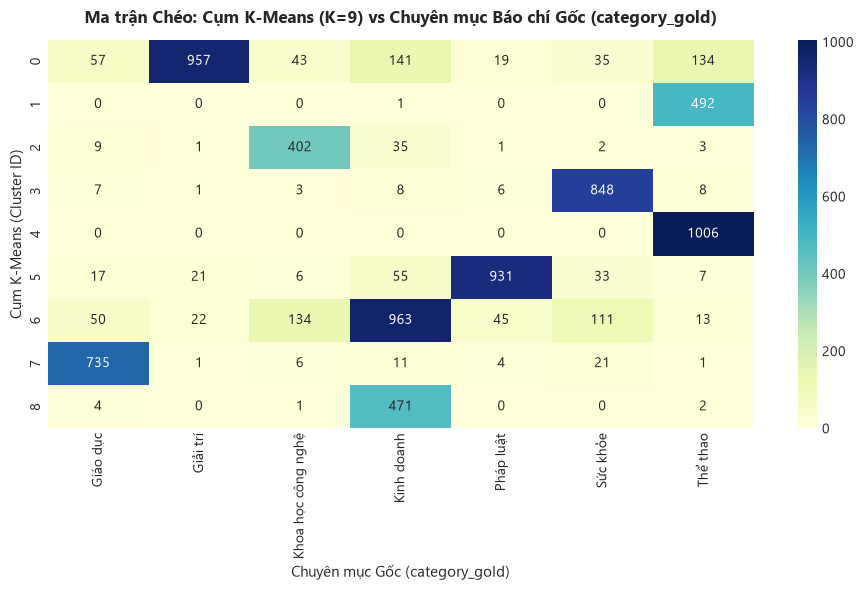

In [62]:
crosstab = pd.crosstab(doc_topics["cluster_id"], doc_topics["category_gold"])

plt.figure(figsize=(9.5, 6))
sns.heatmap(crosstab, annot=True, fmt="d", cmap="YlGnBu", cbar=True, annot_kws={"size": 10})
plt.title("Ma trận Chéo: Cụm K-Means (K=9) vs Chuyên mục Báo chí Gốc (category_gold)", fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Chuyên mục Gốc (category_gold)", fontsize=11)
plt.ylabel("Cụm K-Means (Cluster ID)", fontsize=11)
plt.tight_layout()
plt.show()
